Pre Processing dan Integrasi Data


In [ ]:
# IMPORT LIBRARY
import pandas as pd
import numpy as np
print("Library terpasang. Versi pandas:", pd.__version__)

In [ ]:
# BACA DATA ISPU DAN NORMALISASI NAMA STASIUN
print("Membaca file ISPU...")
ispu = pd.read_html('ispu.xls')[0]
print(f"Ukuran ISPU asli: {ispu.shape[0]} baris x {ispu.shape[1]} kolom")

ispu['hari'] = ispu['tanggal']
ispu = ispu.drop(columns=['tanggal'])

nama_stasiun_standar = {
    'DKI1 BUNDARAN HOTEL INDONESIA (HI)': 'DKI1 Bundaran HI',
    'DKI1 BUNDERAN HI':                    'DKI1 Bundaran HI',
    'DKI1 BUNDARAN HOTEL INDONESIA HI':    'DKI1 Bundaran HI',
    'DKI2 KELAPA GADING':                  'DKI2 Kelapa Gading',
    'DKI3 JAGAKARSA':                      'DKI3 Jagakarsa',
    'DKI4 LUBANG BUAYA':                   'DKI4 Lubang Buaya',
    'DKI5 KEBON JERUK':                    'DKI5 Kebon Jeruk',
    'DKI5 KEBON JERUK JAKARTA BARAT':      'DKI5 Kebon Jeruk',
}
ispu['stasiun'] = ispu['stasiun'].map(nama_stasiun_standar)
print("\nNama stasiun sesudah normalisasi:")
print(ispu['stasiun'].value_counts())

In [ ]:
# BENTUK KOLOM TANGGAL LENGKAP
ispu['tahun'] = ispu['periode_data'].astype(str).str[:4].astype(int)
ispu['bulan'] = ispu['periode_data'].astype(str).str[4:].astype(int)
ispu['tanggal'] = pd.to_datetime(
    dict(year=ispu['tahun'], month=ispu['bulan'], day=ispu['hari']),
    errors='coerce')
baris_awal = len(ispu)
ispu = ispu.dropna(subset=['tanggal']).reset_index(drop=True)
print(f"Baris invalid dibuang: {baris_awal - len(ispu)}")
print(f"Rentang tanggal: {ispu['tanggal'].min().date()} sampai {ispu['tanggal'].max().date()}")

In [ ]:
#  PETAKAN STASIUN
peta_stasiun = {
    'DKI1 Bundaran HI':   {'kota': 'Jakarta Pusat',   'kecamatan': 'MENTENG'},
    'DKI2 Kelapa Gading': {'kota': 'Jakarta Utara',   'kecamatan': 'KELAPA GADING'},
    'DKI3 Jagakarsa':     {'kota': 'Jakarta Selatan', 'kecamatan': 'JAGAKARSA'},
    'DKI4 Lubang Buaya':  {'kota': 'Jakarta Timur',   'kecamatan': 'CIPAYUNG'},
    'DKI5 Kebon Jeruk':   {'kota': 'Jakarta Barat',   'kecamatan': 'KEBON JERUK'},
}
ispu['kota']      = ispu['stasiun'].map(lambda s: peta_stasiun[s]['kota'])
ispu['kecamatan'] = ispu['stasiun'].map(lambda s: peta_stasiun[s]['kecamatan'])
print("Mapping stasiun -> kota & kecamatan:")
print(ispu[['stasiun', 'kota', 'kecamatan']].drop_duplicates().to_string(index=False))

In [ ]:
# KEPADATAN PENDUDUK DARI FILE BPS
kepadatan_kec = {
    (2024, 'MENTENG'): 13019,       (2025, 'MENTENG'): 12959,
    (2024, 'KELAPA GADING'): 9111,  (2025, 'KELAPA GADING'): 9111,
    (2024, 'JAGAKARSA'): 15160,     (2025, 'JAGAKARSA'): 15160,
    (2024, 'CIPAYUNG'): 10791,      (2025, 'CIPAYUNG'): 10718,
    (2024, 'KEBON JERUK'): 20169,   (2025, 'KEBON JERUK'): 20328,
}
ispu['kepadatan_penduduk_jiwa_km2'] = ispu.apply(
    lambda r: kepadatan_kec[(r['tahun'], r['kecamatan'])], axis=1)

print("Kepadatan penduduk per kecamatan per tahun:")
print(ispu.groupby(['tahun', 'kecamatan'])['kepadatan_penduduk_jiwa_km2'].first())

In [ ]:
# RTH DIAGREGASI PER KECAMATAN
print("Membaca file RTH...")
rth = pd.read_excel('rth_2024_2025.xlsx')
rth['luas'] = pd.to_numeric(rth['luas'], errors='coerce')
rth['kecamatan'] = rth['kecamatan'].astype(str).str.upper().str.strip()

salah = (rth['periode_data'] == 2024) & \
        rth['nama_rth'].str.contains('FLY OVER TANJUNG BARAT', na=False) & \
        (rth['luas'] == 1731952)
print("Baris RTH dikoreksi:", salah.sum())   # harus 1
rth.loc[salah, 'luas'] = 17319.52

kec_stasiun = ['MENTENG', 'KELAPA GADING', 'JAGAKARSA', 'CIPAYUNG', 'KEBON JERUK']
rth_kec = (rth[rth['kecamatan'].isin(kec_stasiun)]
           .groupby(['periode_data', 'kecamatan'])['luas'].sum()
           .reset_index())
rth_kec['luas_km2'] = (rth_kec['luas'] / 1_000_000).round(3)

print("Luas RTH total per KECAMATAN per tahun (km2):")
print(rth_kec[['periode_data', 'kecamatan', 'luas_km2']].to_string(index=False))

rth_dict = {}
for _, r in rth_kec.iterrows():
    rth_dict[(int(r['periode_data']), r['kecamatan'])] = r['luas_km2']

def ambil_rth(row):
    return rth_dict.get((row['tahun'], row['kecamatan']), np.nan)
ispu['luas_rth_km2'] = ispu.apply(ambil_rth, axis=1)

print("\nRTH kecamatan berhasil ditambahkan ke ISPU")
print("NaN RTH:", ispu['luas_rth_km2'].isna().sum(), "(harus 0)")
assert ispu['luas_rth_km2'].notna().all(), "Ada baris tanpa nilai RTH kecamatan!"

In [ ]:
# TARIK CUACA PER STASIUN, AGREGASI
import requests, time
koordinat = {
    'DKI1 Bundaran HI':   (-6.1946, 106.8229),
    'DKI2 Kelapa Gading': (-6.1553, 106.9070),
    'DKI3 Jagakarsa':     (-6.3395, 106.8261),
    'DKI4 Lubang Buaya':  (-6.2919, 106.9086),
    'DKI5 Kebon Jeruk':   (-6.1919, 106.7683),
}
def circular_mean(deg):
    rad = np.radians(deg)
    return (np.degrees(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) + 360) % 360

kumpulan = []
for nama, (lat, lon) in koordinat.items():
    print(f'Menarik data {nama}...')
    r = requests.get('https://archive-api.open-meteo.com/v1/archive', params={
        'latitude': lat, 'longitude': lon,
        'start_date': '2024-01-24', 'end_date': '2025-11-08',
        'hourly': ('temperature_2m,relative_humidity_2m,precipitation,cloud_cover,'
                   'wind_speed_10m,surface_pressure,wind_direction_10m'),
        'timezone': 'Asia/Jakarta'}, timeout=60).json()
    d = pd.DataFrame(r['hourly'])
    d['tanggal'] = pd.to_datetime(d['time']).dt.normalize()
    harian = d.groupby('tanggal').agg(
        suhu_c=('temperature_2m','mean'), kelembapan_pct=('relative_humidity_2m','mean'),
        curah_hujan_mm=('precipitation','sum'), tutupan_awan_pct=('cloud_cover','mean'),
        kecepatan_angin_kmh=('wind_speed_10m','mean'), tekanan_hpa=('surface_pressure','mean'),
        arah_angin_deg=('wind_direction_10m', circular_mean)).round(2).reset_index()
    harian['stasiun'] = nama
    kumpulan.append(harian); time.sleep(1)
cuaca_harian = pd.concat(kumpulan, ignore_index=True)
print(f'\nCuaca harian per stasiun: {cuaca_harian.shape}')

In [ ]:
# GABUNGKAN SEMUA
final = ispu.merge(cuaca_harian, on=['tanggal', 'stasiun'], how='inner')
final = final.rename(columns={
    'pm_sepuluh':'pm10', 'pm_duakomalima':'pm25', 'sulfur_dioksida':'so2',
    'karbon_monoksida':'co', 'ozon':'o3', 'nitrogen_dioksida':'no2',
    'parameter_pencemar_kritis':'parameter_kritis'})

kolom_final = [
    'tanggal', 'stasiun', 'kota', 'kecamatan',
    'kepadatan_penduduk_jiwa_km2', 'luas_rth_km2',
    'suhu_c', 'kelembapan_pct', 'curah_hujan_mm', 'tutupan_awan_pct',
    'kecepatan_angin_kmh', 'tekanan_hpa', 'arah_angin_deg',
    'pm10', 'pm25', 'so2', 'co', 'o3', 'no2',
    'max', 'parameter_kritis', 'kategori']
final = final[kolom_final].sort_values(['tanggal', 'stasiun']).reset_index(drop=True)

print("=" * 60)
print("DATASET FINAL (SCOPE KECAMATAN) SIAP!")
print("=" * 60)
print(f"Total baris: {len(final):,} | Total kolom: {len(final.columns)}")
print(f"Periode: {final['tanggal'].min().date()} sampai {final['tanggal'].max().date()}")
print("\nRingkasan novelty per stasiun:")
print(final[['stasiun','kecamatan','kepadatan_penduduk_jiwa_km2','luas_rth_km2']]
      .drop_duplicates().to_string(index=False))
print("\nMissing values:")
print(final.isnull().sum())

In [ ]:
# # SIMPAN & DOWNLOAD
# final.to_excel('dataset_final.xlsx', index=False)
# final.to_csv('dataset_final.csv', index=False)
# print("File tersimpan: dataset_final.xlsx & dataset_final.csv")
# from google.colab import files
# files.download('dataset_final.xlsx')

Pemeriksaan Outlier dan Missing Values

In [ ]:
# ANALISIS OUTLIER & MISSING VALUE
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import files

up = files.upload()
df = pd.read_excel(list(up.keys())[0])
df['tanggal'] = pd.to_datetime(df['tanggal'])
df = df.sort_values(['stasiun', 'tanggal']).reset_index(drop=True)

POL   = ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2']
CUACA = ['suhu_c', 'kelembapan_pct', 'curah_hujan_mm', 'tutupan_awan_pct',
         'kecepatan_angin_kmh', 'tekanan_hpa', 'arah_angin_deg']
NUM = CUACA + POL

In [ ]:
# 1. OUTLIER
BATAS = {
    'suhu_c': (0, 50), 'kelembapan_pct': (0, 100), 'curah_hujan_mm': (0, 500),
    'tutupan_awan_pct': (0, 100), 'kecepatan_angin_kmh': (0, 200),
    'tekanan_hpa': (900, 1100), 'arah_angin_deg': (0, 360),
    **{p: (0, 500) for p in POL}}  # indeks ISPU 0-500
rows = []
for c in NUM:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append(dict(Variabel=c, Min=s.min(), Maks=s.max(),
                     Tidak_Valid=int(((s < BATAS[c][0]) | (s > BATAS[c][1])).sum()),
                     Batas_Bawah_IQR=round(lo, 2), Batas_Atas_IQR=round(hi, 2),
                     Outlier_IQR=int(((s < lo) | (s > hi)).sum()),
                     Persen=round(((s < lo) | (s > hi)).mean() * 100, 2)))
tabel_outlier = pd.DataFrame(rows)
print("=== TABEL OUTLIER ===")
print(tabel_outlier.to_string(index=False))

fig, ax = plt.subplots(2, 1, figsize=(11, 8))
df[POL].boxplot(ax=ax[0]); ax[0].set_title('Boxplot Variabel Polutan (indeks ISPU)')
(df[CUACA] - df[CUACA].mean()).div(df[CUACA].std()).boxplot(ax=ax[1], rot=15)
ax[1].set_title('Boxplot Variabel Meteorologi (distandardisasi)')
plt.tight_layout(); plt.savefig('boxplot_outlier.png', dpi=200); plt.show()

NameError: name 'POL' is not defined

In [ ]:
# 2. MISSING VALUE
def gap_terpanjang(s):
    m = s.isna().astype(int)
    return int(m.groupby((m != m.shift()).cumsum()).sum().max())

rows = []
for c in POL:
    rows.append(dict(Variabel=c, Jumlah_Kosong=int(df[c].isna().sum()),
                     Persen=round(df[c].isna().mean() * 100, 2),
                     Gap_Terpanjang_Hari=max(gap_terpanjang(g[c]) for _, g in df.groupby('stasiun'))))
tabel_missing = pd.DataFrame(rows)
print("\n=== TABEL MISSING VALUE ===")
print(tabel_missing.to_string(index=False))
print("\nMissing per stasiun:")
print(df.groupby('stasiun')[POL].apply(lambda g: g.isna().sum()))

In [ ]:
# 3. PERBANDINGAN METODE PENGISIAN
def isi(s, metode):
    if metode == 'Forward fill (hari sebelumnya)': return s.ffill()
    if metode == 'Interpolasi linear':             return s.interpolate(limit_direction='both')
    if metode == 'Rata-rata (mean)':               return s.fillna(s.mean())
    if metode == 'Median':                         return s.fillna(s.median())

METODE = ['Forward fill (hari sebelumnya)', 'Interpolasi linear', 'Rata-rata (mean)', 'Median']
hasil = {m: {'MAE': [], 'RMSE': []} for m in METODE}
for seed in range(5):
    rng = np.random.default_rng(seed)
    for c in POL:
        for _, g in df.groupby('stasiun'):
            s = g[c].reset_index(drop=True)
            kand = s.index[s.notna() & s.shift(1).notna()]          # punya nilai hari sebelumnya
            idx = rng.choice(kand, size=int(len(kand) * 0.10), replace=False)
            s_mask = s.copy(); s_mask[idx] = np.nan
            for m in METODE:
                e = isi(s_mask, m)[idx] - s[idx]
                e = e.dropna()
                hasil[m]['MAE'].append(e.abs().mean())
                hasil[m]['RMSE'].append(np.sqrt((e ** 2).mean()))
tabel_metode = pd.DataFrame({m: {k: round(np.mean(v), 3) for k, v in hasil[m].items()}
                             for m in METODE}).T.sort_values('MAE')
print("\n=== PERBANDINGAN METODE PENGISIAN (rata-rata 5 percobaan) ===")
print(tabel_metode)

In [ ]:
# 4. CONTOH SEBELUM SESUDAH PENGISIAN
st = df.groupby('stasiun')['pm25'].apply(lambda s: s.isna().sum()).idxmax()
g = df[df['stasiun'] == st].set_index('tanggal')['pm25']
t0 = g[g.isna()].index[0]
jendela = g[t0 - pd.Timedelta(days=10): t0 + pd.Timedelta(days=10)]
contoh = pd.DataFrame({'Sebelum': jendela, 'Sesudah (forward fill)': jendela.ffill()})
print(f"\n=== CONTOH PENGISIAN PM2.5 — {st} ===")
print(contoh.to_string())

plt.figure(figsize=(10, 4))
plt.plot(contoh.index, contoh['Sesudah (forward fill)'], 'o--', color='tab:orange', label='Hasil forward fill')
plt.plot(contoh.index, contoh['Sebelum'], 'o-', color='tab:blue', label='Data asli')
plt.title(f'Contoh Pengisian Missing Value PM2.5 ({st})'); plt.ylabel('Indeks ISPU PM2.5')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig('contoh_pengisian.png', dpi=200); plt.show()


In [ ]:
# 5. SIMPAN SEMUA TABEL
with pd.ExcelWriter('hasil_outlier_missing.xlsx') as w:
    tabel_outlier.to_excel(w, sheet_name='Outlier', index=False)
    tabel_missing.to_excel(w, sheet_name='Missing', index=False)
    tabel_metode.to_excel(w, sheet_name='Perbandingan_Metode')
    contoh.to_excel(w, sheet_name='Contoh_Pengisian')
for f in ['hasil_outlier_missing.xlsx', 'boxplot_outlier.png', 'contoh_pengisian.png']:
    files.download(f)

In [ ]:
   !pip install -q xgboost==3.3.0 scikit-learn==1.6.1 numpy==2.1.3 pandas==2.2.3

Training Model

In [2]:
# Mulai Training

!pip install -q xgboost==3.3.0 >/dev/null 2>&1
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, pickle, json
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats
import xgboost as xgb, time
warnings.filterwarnings('ignore'); np.random.seed(42)
print("xgboost", xgb.__version__)

xgboost 3.3.0


In [3]:
# 1. MUAT DATA
from google.colab import files
up = files.upload()
df = pd.read_excel(list(up.keys())[0])
df['tanggal'] = pd.to_datetime(df['tanggal'])
print("Ukuran awal:", df.shape)

print("\n=== CEK VARIABEL STATIS PER TAHUN ===")
print(df.groupby(['stasiun', df['tanggal'].dt.year])[['kepadatan_penduduk_jiwa_km2','luas_rth_km2']].first())


Saving datasetskripsi.xlsx to datasetskripsi.xlsx
Ukuran awal: (3275, 19)

=== CEK VARIABEL STATIS PER TAHUN ===
                            kepadatan_penduduk_jiwa_km2  luas_rth_km2
stasiun            tanggal                                           
DKI1 Bundaran HI   2024                           13019         0.272
                   2025                           12959         0.273
DKI2 Kelapa Gading 2024                            9111         0.204
                   2025                            9111         0.204
DKI3 Jagakarsa     2024                           15160         1.088
                   2025                           15160         1.121
DKI4 Lubang Buaya  2024                           10791         1.573
                   2025                           10718         1.677
DKI5 Kebon Jeruk   2024                           20169         0.209
                   2025                           20328         0.210


In [4]:
# 2. BUANG KOLOM DATA LEAKAGE (turunan dari PM2.5)
df = df.drop(columns=[c for c in ['max','parameter_kritis','kategori'] if c in df.columns])
df = df.sort_values(['stasiun','tanggal']).reset_index(drop=True)

df['pm25_asli'] = df['pm25'].notna()
pol = ['pm10','pm25','so2','co','o3','no2']
df[pol] = df.groupby('stasiun')[pol].transform(lambda s: s.ffill(limit=7))

In [5]:
# 3. FEATURE ENGINEERING (lag PM2.5 3 hari + rolling + waktu)
g = df.groupby('stasiun')
for lg in [1,2,3]:
    df[f'pm25_lag{lg}'] = g['pm25'].shift(lg)
df['pm25_roll3'] = g['pm25'].transform(lambda s: s.shift(1).rolling(3).mean())
df['bulan'] = df['tanggal'].dt.month
df['hari']  = df['tanggal'].dt.dayofweek


In [6]:
# 4. TARGET 7 HORIZON
g = df.groupby('stasiun')
for h in [1,2,3,4,5,6,7]:
    df[f'target_h{h}']      = g['pm25'].shift(-h)
    df[f'target_h{h}_asli'] = g['pm25_asli'].shift(-h)

FITUR = ['kepadatan_penduduk_jiwa_km2','luas_rth_km2',
         'suhu_c','kelembapan_pct','curah_hujan_mm','tutupan_awan_pct',
         'kecepatan_angin_kmh','tekanan_hpa','arah_angin_deg',
         'pm10','pm25','so2','co','o3','no2',
         'pm25_lag1','pm25_lag2','pm25_lag3','pm25_roll3','bulan','hari']
NOVELTY = ['kepadatan_penduduk_jiwa_km2','luas_rth_km2']

df = df.dropna(subset=['pm25_lag1','pm25_lag2','pm25_lag3','pm25_roll3',
                       'target_h1','target_h2','target_h3',
                       'target_h4','target_h5','target_h6','target_h7']).reset_index(drop=True)
for h in [1,2,3,4,5,6,7]:
    df[f'target_h{h}_asli'] = df[f'target_h{h}_asli'].fillna(False).astype(bool)
print("Baris siap model:", len(df), "(harus 3225) | jumlah fitur:", len(FITUR))

Baris siap model: 3225 (harus 3225) | jumlah fitur: 21


In [7]:
# 5. SPLIT KRONOLOGIS 70 / 15 / 15
tu = np.sort(df['tanggal'].unique()); n = len(tu)
batas_latih, batas_val = tu[int(n*0.70)], tu[int(n*0.85)]
m_tr = df['tanggal'] <  batas_latih
m_va = (df['tanggal'] >= batas_latih) & (df['tanggal'] < batas_val)
m_te = df['tanggal'] >= batas_val
print(f"Train {m_tr.sum()} | Val {m_va.sum()} | Test {m_te.sum()}")

def metrik(y_true, y_pred, asli):
    yt = np.asarray(y_true, float)[asli]; yp = np.asarray(y_pred, float)[asli]
    v = yt != 0
    return dict(MAE=mean_absolute_error(yt,yp),
                RMSE=np.sqrt(mean_squared_error(yt,yp)),
                MAPE=np.mean(np.abs((yt[v]-yp[v])/yt[v]))*100,
                R2=r2_score(yt,yp))

def latih(cols, h, params):
    scl = StandardScaler().fit(df.loc[m_tr, cols])
    Xtr, Xva, Xte = scl.transform(df.loc[m_tr,cols]), scl.transform(df.loc[m_va,cols]), scl.transform(df.loc[m_te,cols])
    ytr, yva, yte = df.loc[m_tr,f'target_h{h}'], df.loc[m_va,f'target_h{h}'], df.loc[m_te,f'target_h{h}']
    m = xgb.XGBRegressor(random_state=42, n_jobs=-1, early_stopping_rounds=50, eval_metric='rmse', **params)
    m.fit(Xtr, ytr, eval_set=[(Xva,yva)], verbose=False)
    a = df.loc[m_te,f'target_h{h}_asli'].values.astype(bool)
    pred = m.predict(Xte)
    return m, scl, metrik(yte, pred, a), pred

Train 2255 | Val 485 | Test 485


In [8]:
# 6. BASELINE (parameter default) per horizon
DEF = dict(n_estimators=600, max_depth=6, learning_rate=0.3,
           subsample=1.0, colsample_bytree=1.0,
           min_child_weight=1, reg_alpha=0.0, reg_lambda=1.0)
print("\n=== BASELINE per horizon ===")
base = {}
t0 = time.perf_counter()
for h in [1,2,3,4,5,6,7]:
    _,_,r,_ = latih(FITUR, h, DEF); base[h]=r
    print(f"t+{h}: MAE={r['MAE']:.3f} RMSE={r['RMSE']:.3f} MAPE={r['MAPE']:.2f}% R2={r['R2']:.3f}")

waktu_bawaan = time.perf_counter() - t0
print(f"Waktu latih 7 model bawaan: {waktu_bawaan:.1f} detik")


=== BASELINE per horizon ===
t+1: MAE=10.459 RMSE=13.486 MAPE=13.34% R2=0.168
t+2: MAE=12.378 RMSE=15.725 MAPE=15.78% R2=-0.136
t+3: MAE=13.004 RMSE=16.374 MAPE=16.83% R2=-0.232
t+4: MAE=12.643 RMSE=15.923 MAPE=16.25% R2=-0.154
t+5: MAE=11.715 RMSE=14.996 MAPE=15.73% R2=0.055
t+6: MAE=12.267 RMSE=15.431 MAPE=16.47% R2=0.038
t+7: MAE=11.870 RMSE=15.187 MAPE=17.19% R2=0.127
Waktu latih 7 model bawaan: 5.9 detik



=== PSO ===
Iter  0 | gbest RMSE(val) = 16.3291
Iter  1 | w=0.888 | gbest RMSE(val) = 16.2195
Iter  2 | w=0.875 | gbest RMSE(val) = 16.0810
Iter  3 | w=0.863 | gbest RMSE(val) = 16.0527
Iter  4 | w=0.850 | gbest RMSE(val) = 16.0329
Iter  5 | w=0.838 | gbest RMSE(val) = 16.0329
Iter  6 | w=0.825 | gbest RMSE(val) = 16.0329
Iter  7 | w=0.812 | gbest RMSE(val) = 16.0329
Iter  8 | w=0.800 | gbest RMSE(val) = 16.0329
Iter  9 | w=0.787 | gbest RMSE(val) = 16.0329
Iter 10 | w=0.775 | gbest RMSE(val) = 16.0329
Iter 11 | w=0.762 | gbest RMSE(val) = 16.0329
Iter 12 | w=0.750 | gbest RMSE(val) = 15.9054
Iter 13 | w=0.738 | gbest RMSE(val) = 15.9054
Iter 14 | w=0.725 | gbest RMSE(val) = 15.9054
Iter 15 | w=0.713 | gbest RMSE(val) = 15.9054
Iter 16 | w=0.700 | gbest RMSE(val) = 15.9054
Iter 17 | w=0.688 | gbest RMSE(val) = 15.9054
Iter 18 | w=0.675 | gbest RMSE(val) = 15.9054
Iter 19 | w=0.663 | gbest RMSE(val) = 15.9054
Iter 20 | w=0.650 | gbest RMSE(val) = 15.9054
Iter 21 | w=0.637 | gbest RMSE(

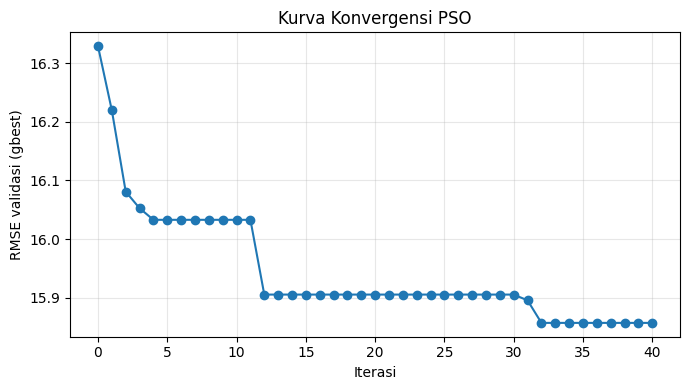

In [9]:
# 7. OPTIMASI PSO
BB = np.array([3, 0.01, 0.50, 0.50, 1, 0.00, 0.50])    # batas bawah
BA = np.array([10, 0.30, 1.00, 1.00, 10, 2.00, 5.00])  # batas atas
def dekode(p):
    return dict(max_depth=int(round(p[0])), learning_rate=float(p[1]),
                subsample=float(p[2]), colsample_bytree=float(p[3]),
                min_child_weight=int(round(p[4])), reg_alpha=float(p[5]),
                reg_lambda=float(p[6]), n_estimators=600)

scl1 = StandardScaler().fit(df.loc[m_tr, FITUR])
Xtr1, Xva1 = scl1.transform(df.loc[m_tr,FITUR]), scl1.transform(df.loc[m_va,FITUR])
ytr1, yva1 = df.loc[m_tr,'target_h1'], df.loc[m_va,'target_h1']
cache = {}
def fitness(p):
    pr = dekode(p); key = tuple(round(v,4) if isinstance(v,float) else v for v in pr.values())
    if key in cache: return cache[key]
    m = xgb.XGBRegressor(random_state=42, n_jobs=-1, early_stopping_rounds=50, eval_metric='rmse', **pr)
    m.fit(Xtr1, ytr1, eval_set=[(Xva1,yva1)], verbose=False)
    r = np.sqrt(mean_squared_error(yva1, m.predict(Xva1))); cache[key]=r; return r

t0 = time.perf_counter()
rng = np.random.default_rng(42)
N_PARTIKEL, N_ITERASI = 20, 40
w_awal, w_akhir, c1, c2 = 0.9, 0.4, 1.5, 1.5
rentang = BA - BB
pos = BB + rng.random((N_PARTIKEL,7))*rentang
vmax = 0.5*rentang
vel = rng.uniform(-1,1,(N_PARTIKEL,7))*vmax
skor = np.array([fitness(p) for p in pos])
pbest, pbs = pos.copy(), skor.copy()
gi = int(np.argmin(pbs)); gbest = pbest[gi].copy(); gbs = float(pbs[gi])
riwayat = [gbs]
print(f"\n=== PSO ===\nIter  0 | gbest RMSE(val) = {gbs:.4f}")
for it in range(1, N_ITERASI+1):
    w = w_awal - (w_awal - w_akhir) * it / N_ITERASI
    for i in range(N_PARTIKEL):
        r1, r2 = rng.random(7), rng.random(7)
        vel[i] = np.clip(w*vel[i] + c1*r1*(pbest[i]-pos[i]) + c2*r2*(gbest-pos[i]), -vmax, vmax)
        pos[i] = np.clip(pos[i]+vel[i], BB, BA)
        s = fitness(pos[i])
        if s < pbs[i]:
            pbs[i], pbest[i] = s, pos[i].copy()
            if s < gbs: gbs, gbest = float(s), pos[i].copy()
    riwayat.append(gbs)
    print(f"Iter {it:2d} | w={w:.3f} | gbest RMSE(val) = {gbs:.4f}")
BEST = dekode(gbest)
waktu_pso = time.perf_counter() - t0
n_unik_pso = len(cache)
print(f"Waktu pencarian PSO: {waktu_pso:.1f} detik | kombinasi unik: {n_unik_pso}")
print("\nHyperparameter terbaik:", {k:(round(v,4) if isinstance(v,float) else v) for k,v in BEST.items()})

plt.figure(figsize=(7,4))
plt.plot(range(len(riwayat)), riwayat, marker='o')
plt.xlabel('Iterasi'); plt.ylabel('RMSE validasi (gbest)')
plt.title('Kurva Konvergensi PSO'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [10]:
# 8. MODEL FINAL (XGBoost + PSO) per horizon
print("\n=== XGBoost + PSO per horizon ===")
pso = {}
t0 = time.perf_counter()
for h in [1,2,3,4,5,6,7]:
    m, scl, r, _ = latih(FITUR, h, BEST); pso[h]=r
    with open(f'model_pm25_h{h}.pkl','wb') as f:
        pickle.dump({'model':m, 'scaler':scl, 'fitur':FITUR, 'horizon':h}, f)
    print(f"t+{h}: MAE={r['MAE']:.3f} RMSE={r['RMSE']:.3f} MAPE={r['MAPE']:.2f}% R2={r['R2']:.3f}  -> model_pm25_h{h}.pkl")

waktu_final_pso = time.perf_counter() - t0
print(f"Waktu latih 7 model final PSO: {waktu_final_pso:.1f} detik")


=== XGBoost + PSO per horizon ===
t+1: MAE=9.841 RMSE=12.522 MAPE=12.60% R2=0.283  -> model_pm25_h1.pkl
t+2: MAE=11.386 RMSE=14.318 MAPE=14.55% R2=0.058  -> model_pm25_h2.pkl
t+3: MAE=11.230 RMSE=14.190 MAPE=14.68% R2=0.075  -> model_pm25_h3.pkl
t+4: MAE=11.524 RMSE=14.505 MAPE=15.04% R2=0.042  -> model_pm25_h4.pkl
t+5: MAE=11.692 RMSE=14.811 MAPE=15.47% R2=0.078  -> model_pm25_h5.pkl
t+6: MAE=11.688 RMSE=14.692 MAPE=15.78% R2=0.128  -> model_pm25_h6.pkl
t+7: MAE=11.509 RMSE=14.430 MAPE=16.28% R2=0.212  -> model_pm25_h7.pkl
Waktu latih 7 model final PSO: 1.1 detik


In [11]:
# 9. TABEL RINGKAS Baseline vs PSO
print("\n"+"="*64)
print(f"{'Horizon':9s}{'Model':10s}{'MAE':>9s}{'RMSE':>9s}{'MAPE':>9s}{'R2':>9s}")
print("="*64)
for h in [1,2,3,4,5,6,7]:
    for nm, r in [('Baseline',base[h]),('XGB+PSO',pso[h])]:
        print(f"{'t+'+str(h):9s}{nm:10s}{r['MAE']:9.3f}{r['RMSE']:9.3f}{r['MAPE']:8.2f}%{r['R2']:9.3f}")


Horizon  Model           MAE     RMSE     MAPE       R2
t+1      Baseline     10.459   13.486   13.34%    0.168
t+1      XGB+PSO       9.841   12.522   12.60%    0.283
t+2      Baseline     12.378   15.725   15.78%   -0.136
t+2      XGB+PSO      11.386   14.318   14.55%    0.058
t+3      Baseline     13.004   16.374   16.83%   -0.232
t+3      XGB+PSO      11.230   14.190   14.68%    0.075
t+4      Baseline     12.643   15.923   16.25%   -0.154
t+4      XGB+PSO      11.524   14.505   15.04%    0.042
t+5      Baseline     11.715   14.996   15.73%    0.055
t+5      XGB+PSO      11.692   14.811   15.47%    0.078
t+6      Baseline     12.267   15.431   16.47%    0.038
t+6      XGB+PSO      11.688   14.692   15.78%    0.128
t+7      Baseline     11.870   15.187   17.19%    0.127
t+7      XGB+PSO      11.509   14.430   16.28%    0.212


In [12]:
# 10. SKENARIO S1/S2/S3
df = pd.concat([df, pd.get_dummies(df['stasiun'], prefix='st').astype(int)], axis=1)
ST = [c for c in df.columns if c.startswith('st_')]
DASAR = [c for c in FITUR if c not in NOVELTY]
def dm_test(y, p1, p2, h=1):
    e1, e2 = y-p1, y-p2; d = e1**2 - e2**2; nT=len(d); g0=np.var(d,ddof=0)
    gm=[np.cov(d[k:],d[:-k])[0,1] for k in range(1,h)] if h>1 else []
    vd=(g0+2*sum(gm))/nT
    if vd<=0: return np.nan, np.nan
    s=np.mean(d)/np.sqrt(vd); return s, 2*(1-stats.t.cdf(abs(s),nT-1))

print("\n=== S1/S2/S3 + Diebold-Mariano (S1 vs S3) ===")
skenario_json, baris_sk = {}, []
for h in [1,2,3,4,5,6,7]:
    _,_,r1,p1 = latih(DASAR,     h, BEST)
    _,_,r2,_  = latih(DASAR+ST,  h, BEST)
    _,_,r3,p3 = latih(FITUR, h, BEST)
    a = df.loc[m_te,f'target_h{h}_asli'].values.astype(bool)
    yt = df.loc[m_te,f'target_h{h}'].values[a]
    s, pv = dm_test(yt, p1[a], p3[a], h)
    print(f"t+{h}: S1={r1['RMSE']:.3f} S2={r2['RMSE']:.3f} S3={r3['RMSE']:.3f} | DM={s:.3f} p={pv:.4f}")
    for nama, r in [('S1', r1), ('S2', r2), ('S3', r3)]:
        baris_sk.append({'Horizon': f't+{h}', 'Skenario': nama, **{k: round(float(v), 3) for k, v in r.items()}})
    skenario_json[str(h)] = {'S1': round(r1['RMSE'], 3), 'S2': round(r2['RMSE'], 3), 'S3': round(r3['RMSE'], 3),
                             'DM': round(float(s), 3), 'p': round(float(pv), 4),
                             'lengkap': {nm: {k: round(float(v), 3) for k, v in r.items()}
                                         for nm, r in [('S1', r1), ('S2', r2), ('S3', r3)]}}

tabel_sk_lengkap = pd.DataFrame(baris_sk)
print(tabel_sk_lengkap.to_string(index=False))
print(tabel_sk_lengkap.groupby('Skenario')[['MAE','RMSE','MAPE','R2']].mean().round(3))
with open('hasil_skenario.json', 'w') as f:
    json.dump({'sumber': 'Output Colab sel 10, hyperparameter BEST PSO',
               'metrik': 'RMSE data uji (hanya nilai PM2.5 asli)', 'skenario': skenario_json}, f, indent=2)
tabel_sk_lengkap.to_excel('tabel_skenario_lengkap.xlsx', index=False)


=== S1/S2/S3 + Diebold-Mariano (S1 vs S3) ===
t+1: S1=12.352 S2=12.451 S3=12.522 | DM=-1.687 p=0.0922
t+2: S1=14.040 S2=14.105 S3=14.318 | DM=-1.717 p=0.0867
t+3: S1=13.993 S2=13.899 S3=14.190 | DM=-1.280 p=0.2013
t+4: S1=14.278 S2=14.409 S3=14.505 | DM=-1.251 p=0.2114
t+5: S1=14.646 S2=14.408 S3=14.811 | DM=-0.837 p=0.4032
t+6: S1=14.800 S2=14.941 S3=14.692 | DM=0.555 p=0.5792
t+7: S1=14.548 S2=14.643 S3=14.430 | DM=0.550 p=0.5825
Horizon Skenario    MAE   RMSE   MAPE    R2
    t+1       S1  9.683 12.352 12.505 0.302
    t+1       S2  9.771 12.451 12.586 0.291
    t+1       S3  9.841 12.522 12.602 0.283
    t+2       S1 11.158 14.040 14.295 0.095
    t+2       S2 11.289 14.105 14.486 0.086
    t+2       S3 11.386 14.318 14.552 0.058
    t+3       S1 10.942 13.993 14.404 0.100
    t+3       S2 11.029 13.899 14.441 0.112
    t+3       S3 11.230 14.190 14.679 0.075
    t+4       S1 11.337 14.278 14.890 0.072
    t+4       S2 11.467 14.409 15.078 0.055
    t+4       S3 11.524 14.505 15.0

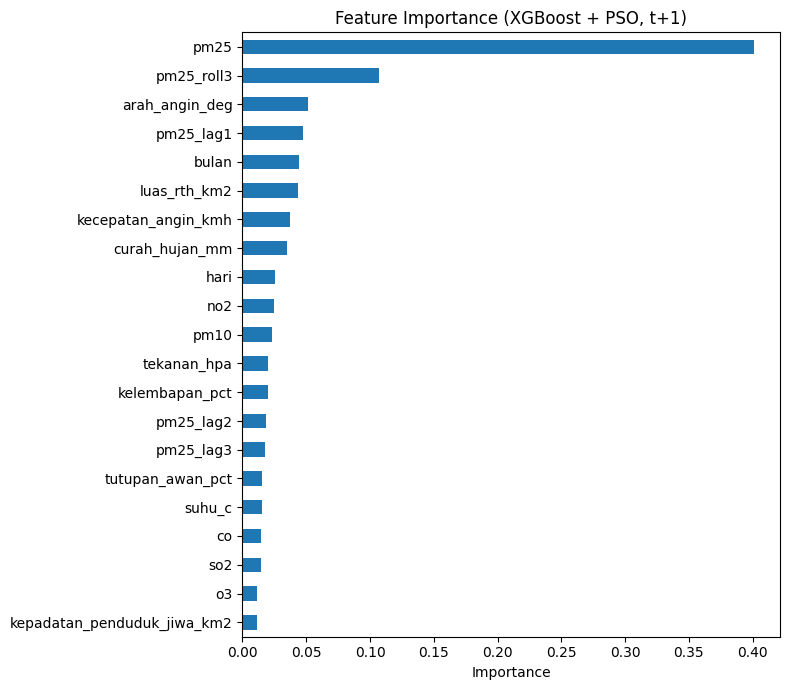


Peringkat novelty (t+1):
  kepadatan_penduduk_jiwa_km2: peringkat 21 dari 21
  luas_rth_km2: peringkat 6 dari 21


In [13]:
# 11. FEATURE IMPORTANCE
m1, scl1b, _, _ = latih(FITUR, 1, BEST)
imp = pd.Series(m1.feature_importances_, index=FITUR).sort_values()
plt.figure(figsize=(8,7)); imp.plot(kind='barh')
plt.title('Feature Importance (XGBoost + PSO, t+1)'); plt.xlabel('Importance')
plt.tight_layout(); plt.show()
print("\nPeringkat novelty (t+1):")
imp_desc = imp.sort_values(ascending=False)
for f in NOVELTY:
    print(f"  {f}: peringkat {list(imp_desc.index).index(f)+1} dari {len(FITUR)}")

In [14]:
# 12. BASELINE PERSISTENCE
print("\n=== BASELINE PERSISTENCE (naif) vs XGB+PSO ===")
pm_te_hari_ini = df.loc[m_te, 'pm25'].values
persist = {}
for h in [1,2,3,4,5,6,7]:
    a  = df.loc[m_te, f'target_h{h}_asli'].values.astype(bool)
    yt = df.loc[m_te, f'target_h{h}'].values
    r  = metrik(yt, pm_te_hari_ini, a)
    persist[h] = r
    menang = "menang" if pso[h]['RMSE'] < r['RMSE'] else "KALAH"
    print(f"t+{h}: Persistence RMSE={r['RMSE']:.3f} R2={r['R2']:.3f}  |  "
          f"XGB+PSO RMSE={pso[h]['RMSE']:.3f} R2={pso[h]['R2']:.3f}  ({menang})")


=== BASELINE PERSISTENCE (naif) vs XGB+PSO ===
t+1: Persistence RMSE=15.109 R2=-0.044  |  XGB+PSO RMSE=12.522 R2=0.283  (menang)
t+2: Persistence RMSE=16.557 R2=-0.259  |  XGB+PSO RMSE=14.318 R2=0.058  (menang)
t+3: Persistence RMSE=17.688 R2=-0.438  |  XGB+PSO RMSE=14.190 R2=0.075  (menang)
t+4: Persistence RMSE=18.677 R2=-0.588  |  XGB+PSO RMSE=14.505 R2=0.042  (menang)
t+5: Persistence RMSE=18.433 R2=-0.429  |  XGB+PSO RMSE=14.811 R2=0.078  (menang)
t+6: Persistence RMSE=19.160 R2=-0.483  |  XGB+PSO RMSE=14.692 R2=0.128  (menang)
t+7: Persistence RMSE=18.634 R2=-0.314  |  XGB+PSO RMSE=14.430 R2=0.212  (menang)


In [15]:
# 13. UJI KESTABILAN MULTI-SEED
SEEDS = [42, 1, 7, 123, 2024]
def latih_seed(cols, h, params, seed):
    p = dict(params); p['random_state'] = seed
    scl = StandardScaler().fit(df.loc[m_tr, cols])
    Xtr, Xva, Xte = scl.transform(df.loc[m_tr,cols]), scl.transform(df.loc[m_va,cols]), scl.transform(df.loc[m_te,cols])
    ytr, yva, yte = df.loc[m_tr,f'target_h{h}'], df.loc[m_va,f'target_h{h}'], df.loc[m_te,f'target_h{h}']
    m = xgb.XGBRegressor(n_jobs=-1, early_stopping_rounds=50, eval_metric='rmse', **p)
    m.fit(Xtr, ytr, eval_set=[(Xva,yva)], verbose=False)
    a = df.loc[m_te,f'target_h{h}_asli'].values.astype(bool)
    return metrik(yte, m.predict(Xte), a)

print(f"\n=== KESTABILAN MULTI-SEED (XGB+PSO, {len(SEEDS)} seed) ===")
print(f"{'Horizon':9s}{'RMSE (mean±std)':>20s}{'R2 (mean±std)':>20s}")
for h in [1,2,3,4,5,6,7]:
    res   = [latih_seed(FITUR, h, BEST, s) for s in SEEDS]
    rmses = [x['RMSE'] for x in res]; r2s = [x['R2'] for x in res]
    print(f"{'t+'+str(h):9s}{np.mean(rmses):8.3f} ± {np.std(rmses):.3f}   {np.mean(r2s):8.3f} ± {np.std(r2s):.3f}")


=== KESTABILAN MULTI-SEED (XGB+PSO, 5 seed) ===
Horizon       RMSE (mean±std)       R2 (mean±std)
t+1        12.550 ± 0.143      0.280 ± 0.017
t+2        14.163 ± 0.090      0.079 ± 0.012
t+3        14.096 ± 0.068      0.087 ± 0.009
t+4        14.693 ± 0.114      0.017 ± 0.015
t+5        14.880 ± 0.260      0.069 ± 0.032
t+6        14.783 ± 0.103      0.117 ± 0.012
t+7        14.499 ± 0.053      0.205 ± 0.006



=== RANDOM SEARCH (820 evaluasi) ===
Waktu pencarian Random Search: 419.0 detik | kombinasi unik: 820
RMSE(val) terbaik RS = 15.8173 | PSO = 15.8571
Hyperparameter RS: {'max_depth': 4, 'learning_rate': 0.2802, 'subsample': 0.7652, 'colsample_bytree': 0.5891, 'min_child_weight': 7, 'reg_alpha': 0.3838, 'reg_lambda': 0.7859, 'n_estimators': 600}


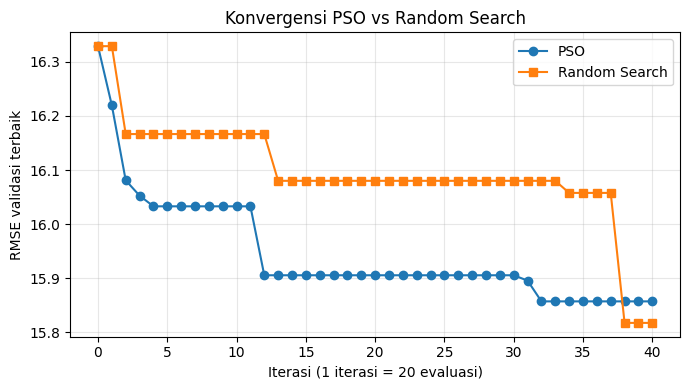


Horizon  Model           MAE     RMSE     MAPE       R2
t+1      Default      10.459   13.486   13.34%    0.168
t+1      RandomS       9.929   12.796   12.97%    0.251
t+1      PSO           9.841   12.522   12.60%    0.283
         DM RS vs PSO = 1.398, p = 0.1629 (PSO lebih baik, tidak signifikan)
------------------------------------------------------------------------
t+2      Default      12.378   15.725   15.78%   -0.136
t+2      RandomS      11.570   14.460   15.25%    0.040
t+2      PSO          11.386   14.318   14.55%    0.058
         DM RS vs PSO = 0.464, p = 0.6431 (PSO lebih baik, tidak signifikan)
------------------------------------------------------------------------
t+3      Default      13.004   16.374   16.83%   -0.232
t+3      RandomS      11.360   14.311   14.92%    0.059
t+3      PSO          11.230   14.190   14.68%    0.075
         DM RS vs PSO = 0.540, p = 0.5895 (PSO lebih baik, tidak signifikan)
--------------------------------------------------------------

In [16]:
# 14. PEMBANDING: RANDOM SEARCH
N_EVAL_RS = N_PARTIKEL * (N_ITERASI + 1)
cache.clear()
t0 = time.perf_counter()
rng_rs = np.random.default_rng(42)

best_rs, best_rs_skor = None, np.inf
riwayat_rs = []
print(f"\n=== RANDOM SEARCH ({N_EVAL_RS} evaluasi) ===")
for i in range(N_EVAL_RS):
    p = BB + rng_rs.random(7) * rentang
    s = fitness(p)
    if s < best_rs_skor:
        best_rs_skor, best_rs = s, p.copy()
    if (i + 1) % N_PARTIKEL == 0:
        riwayat_rs.append(best_rs_skor)
BEST_RS = dekode(best_rs)
waktu_rs = time.perf_counter() - t0
n_unik_rs = len(cache)
print(f"Waktu pencarian Random Search: {waktu_rs:.1f} detik | kombinasi unik: {n_unik_rs}")
print(f"RMSE(val) terbaik RS = {best_rs_skor:.4f} | PSO = {gbs:.4f}")
print("Hyperparameter RS:", {k:(round(v,4) if isinstance(v,float) else v) for k,v in BEST_RS.items()})


plt.figure(figsize=(7,4))
plt.plot(range(len(riwayat)), riwayat, marker='o', label='PSO')
plt.plot(range(len(riwayat_rs)), riwayat_rs, marker='s', label='Random Search')
plt.xlabel(f'Iterasi (1 iterasi = {N_PARTIKEL} evaluasi)'); plt.ylabel('RMSE validasi terbaik')
plt.title('Konvergensi PSO vs Random Search'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("\n" + "="*72)
print(f"{'Horizon':9s}{'Model':10s}{'MAE':>9s}{'RMSE':>9s}{'MAPE':>9s}{'R2':>9s}")
print("="*72)
rs = {}
waktu_final_rs = 0.0
for h in [1,2,3,4,5,6,7]:
    t1 = time.perf_counter()
    _,_,r_rs,p_rs  = latih(FITUR, h, BEST_RS); rs[h] = r_rs
    waktu_final_rs += time.perf_counter() - t1
    _,_,_,  p_pso  = latih(FITUR, h, BEST)
    for nm, r in [('Default',base[h]), ('RandomS',r_rs), ('PSO',pso[h])]:
        print(f"{'t+'+str(h):9s}{nm:10s}{r['MAE']:9.3f}{r['RMSE']:9.3f}{r['MAPE']:8.2f}%{r['R2']:9.3f}")
    a  = df.loc[m_te, f'target_h{h}_asli'].values.astype(bool)
    yt = df.loc[m_te, f'target_h{h}'].values[a]
    s, pv = dm_test(yt, p_rs[a], p_pso[a], h)
    arah = 'PSO lebih baik' if s > 0 else 'RS lebih baik'
    sig  = 'SIGNIFIKAN' if (not np.isnan(pv) and pv < 0.05) else 'tidak signifikan'
    print(f"{'':9s}DM RS vs PSO = {s:.3f}, p = {pv:.4f} ({arah}, {sig})")
    print("-"*72)

In [17]:
def periode(t):
    if t < pd.Timestamp('2025-09-01'): return 'Agustus (29 Jul–31 Agu)'
    if t < pd.Timestamp('2025-10-01'): return 'September'
    return 'Okt–Nov (1 Okt–8 Nov)'

baris = []
for h in [1,2,3,4,5,6,7]:
    _, _, _, pred = latih(FITUR, h, BEST)
    uji = df.loc[m_te, ['tanggal', f'target_h{h}', f'target_h{h}_asli']].copy()
    uji['pred'] = pred
    uji = uji[uji[f'target_h{h}_asli']]
    uji['periode'] = (uji['tanggal'] + pd.Timedelta(days=h)).map(periode)
    for p, g in uji.groupby('periode'):
        r = metrik(g[f'target_h{h}'], g['pred'], np.ones(len(g), bool))
        baris.append({'Horizon': f't+{h}', 'Periode': p, 'n': len(g),
                      **{k: round(v, 3) for k, v in r.items()}})

tabel_periode = pd.DataFrame(baris)
print(tabel_periode.to_string(index=False))
tabel_periode.to_excel('tabel_metrik_periode.xlsx', index=False)
files.download('tabel_metrik_periode.xlsx')

Horizon                 Periode   n    MAE   RMSE   MAPE     R2
    t+1 Agustus (29 Jul–31 Agu) 164 10.260 12.919 13.344  0.243
    t+1   Okt–Nov (1 Okt–8 Nov) 163  9.062 11.530 12.345  0.428
    t+1               September 146 10.240 13.119 12.054 -0.032
    t+2 Agustus (29 Jul–31 Agu) 160 11.011 13.626 14.262  0.159
    t+2   Okt–Nov (1 Okt–8 Nov) 168 11.459 14.409 15.776  0.087
    t+2               September 146 11.713 14.940 13.462 -0.338
    t+3 Agustus (29 Jul–31 Agu) 155 11.155 13.853 14.738  0.139
    t+3   Okt–Nov (1 Okt–8 Nov) 173 11.551 14.473 16.303  0.071
    t+3               September 146 10.928 14.203 12.692 -0.209
    t+4 Agustus (29 Jul–31 Agu) 150 11.291 13.950 14.720  0.139
    t+4   Okt–Nov (1 Okt–8 Nov) 178 12.064 14.990 17.192 -0.002
    t+4               September 146 11.105 14.462 12.734 -0.254
    t+5 Agustus (29 Jul–31 Agu) 145 12.496 15.037 16.382  0.023
    t+5   Okt–Nov (1 Okt–8 Nov) 183 11.949 15.499 17.370  0.065
    t+5               September 146 10.5

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
waktu = pd.DataFrame([
    {'Metode': 'XGBoost bawaan', 'Pencarian (detik)': 0.0, 'Latih 7 model (detik)': waktu_bawaan, 'Kombinasi unik': 1},
    {'Metode': 'Random Search', 'Pencarian (detik)': waktu_rs, 'Latih 7 model (detik)': waktu_final_rs, 'Kombinasi unik': n_unik_rs},
    {'Metode': 'PSO', 'Pencarian (detik)': waktu_pso, 'Latih 7 model (detik)': waktu_final_pso, 'Kombinasi unik': n_unik_pso},
])
waktu['Total (menit)'] = (waktu['Pencarian (detik)'] + waktu['Latih 7 model (detik)']) / 60
print(waktu.round(2).to_string(index=False))
waktu.round(2).to_excel('tabel_waktu_komputasi.xlsx', index=False)
for f in ['hasil_skenario.json', 'tabel_skenario_lengkap.xlsx', 'tabel_waktu_komputasi.xlsx']:
    files.download(f)

        Metode  Pencarian (detik)  Latih 7 model (detik)  Kombinasi unik  Total (menit)
XGBoost bawaan               0.00                   5.90               1           0.10
 Random Search             419.02                   0.72             820           7.00
           PSO             186.35                   1.07             820           3.12


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
for nama, m in [('Latih', m_tr), ('Validasi', m_va), ('Uji', m_te)]:
    g = df[m & df['pm25_asli']]
    ak = np.mean([x.sort_values('tanggal')['pm25'].where(x['pm25_asli']).autocorr(1)
                  for _, x in df[m].groupby('stasiun')])
    print(f"{nama}: n={m.sum()} rata-rata={g['pm25'].mean():.2f} SD={g['pm25'].std(ddof=0):.2f} "
          f">100={(g['pm25']>100).mean()*100:.1f}% autokorelasi={ak:.3f}")

_, _, _, pred = latih(FITUR, 1, BEST)
a  = df.loc[m_te, 'target_h1_asli'].values.astype(bool)
y  = df.loc[m_te, 'target_h1'].values[a]; yh = pred[a]; e = y - yh
rmse = np.sqrt(np.mean(e**2))
print(f"SD aktual={y.std():.2f} | SD prediksi={yh.std():.2f} | RMSE={rmse:.3f} | R2={1-(rmse/y.std())**2:.3f}")
se = np.sort(e**2)[::-1]
print(f"10% error terbesar menyumbang {se[:len(se)//10].sum()/se.sum()*100:.1f}% total error kuadrat")
besar = np.abs(e) > 2*rmse
print(f"data dengan error > 2xRMSE: {besar.sum()} | R2 tanpa data tersebut: {r2_score(y[~besar], yh[~besar]):.3f}")
lonjak = y > 100
print(f"data aktual >100: {lonjak.sum()} | rata aktual {y[lonjak].mean():.1f} | rata prediksi {yh[lonjak].mean():.1f}")

Latih: n=2255 rata-rata=68.08 SD=23.66 >100=7.7% autokorelasi=0.706
Validasi: n=485 rata-rata=87.81 SD=18.93 >100=26.1% autokorelasi=0.371
Uji: n=485 rata-rata=79.58 SD=14.75 >100=7.8% autokorelasi=0.407
SD aktual=14.79 | SD prediksi=10.36 | RMSE=12.522 | R2=0.283
10% error terbesar menyumbang 45.6% total error kuadrat
data dengan error > 2xRMSE: 21 | R2 tanpa data tersebut: 0.388
data aktual >100: 37 | rata aktual 107.8 | rata prediksi 85.4


In [20]:
# Simpan Evaluasi
with open('hasil_evaluasi.json','w') as f:
    json.dump({'default':base, 'random_search':rs, 'pso':pso, 'persistence':persist,
               'best_pso':BEST, 'best_rs':BEST_RS}, f, indent=2, default=float)

# from google.colab import files
# for h in [1,2,3,4,5,6,7]: files.download(f'model_pm25_h{h}.pkl')
# files.download('hasil_evaluasi.json')
print("\nSELESAI. Tersimpan: model_pm25_h1.pkl ... model_pm25_h7.pkl + hasil_evaluasi.json")


SELESAI. Tersimpan: model_pm25_h1.pkl ... model_pm25_h7.pkl + hasil_evaluasi.json


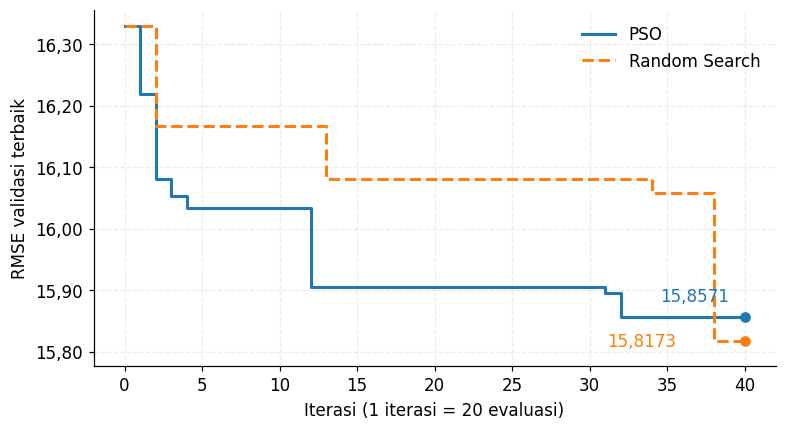

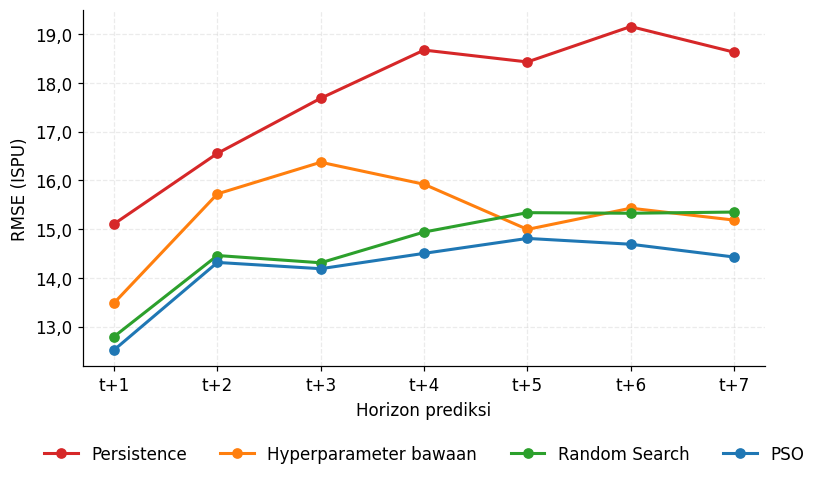

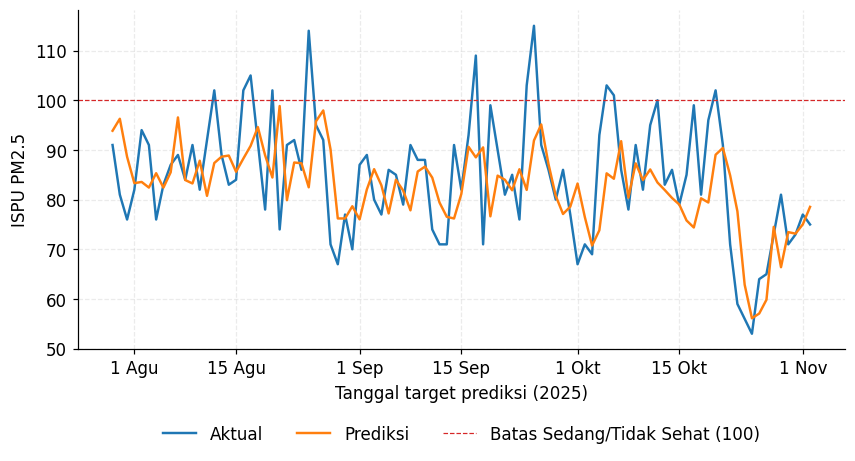

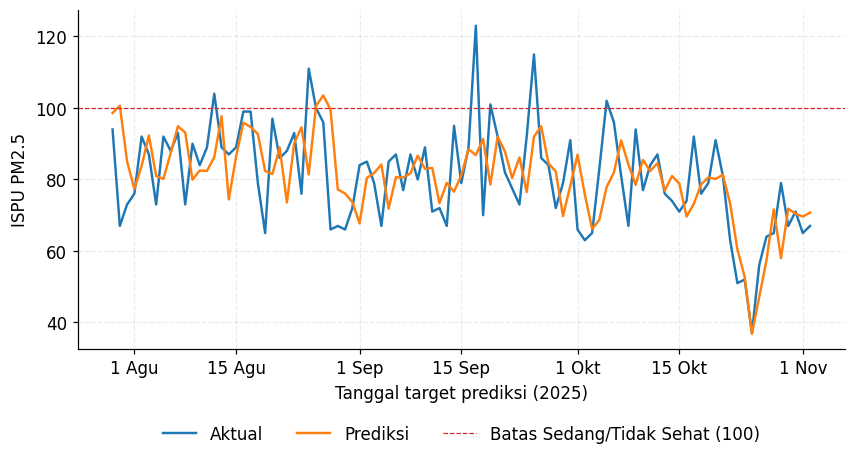

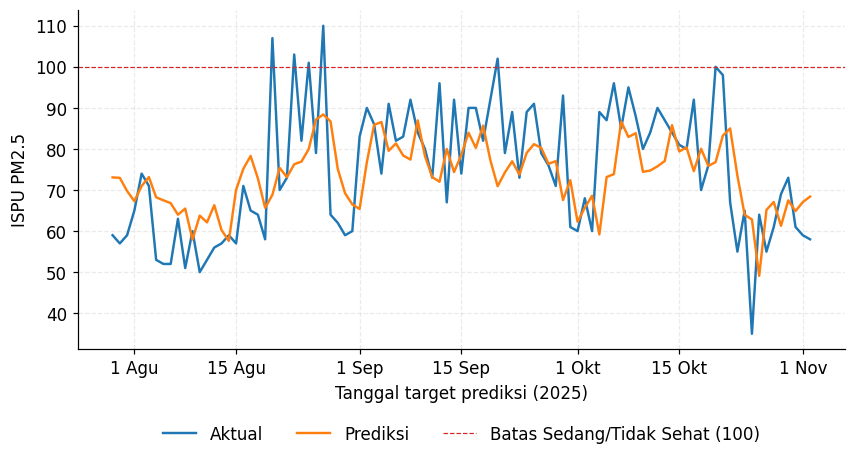

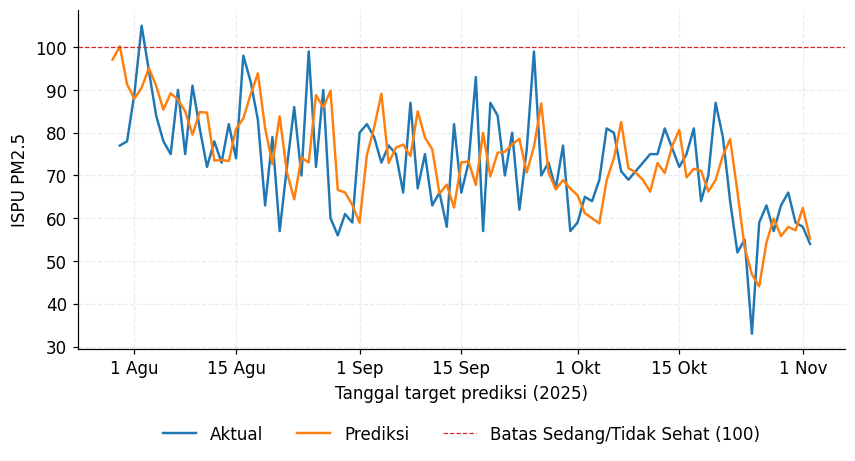

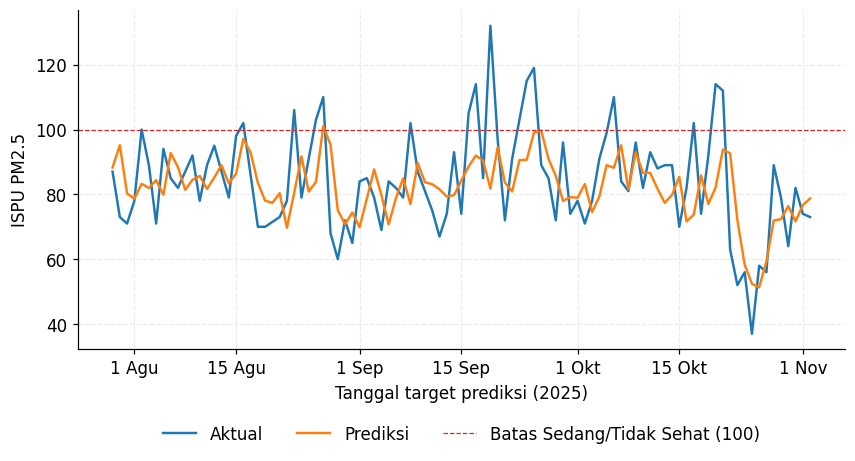

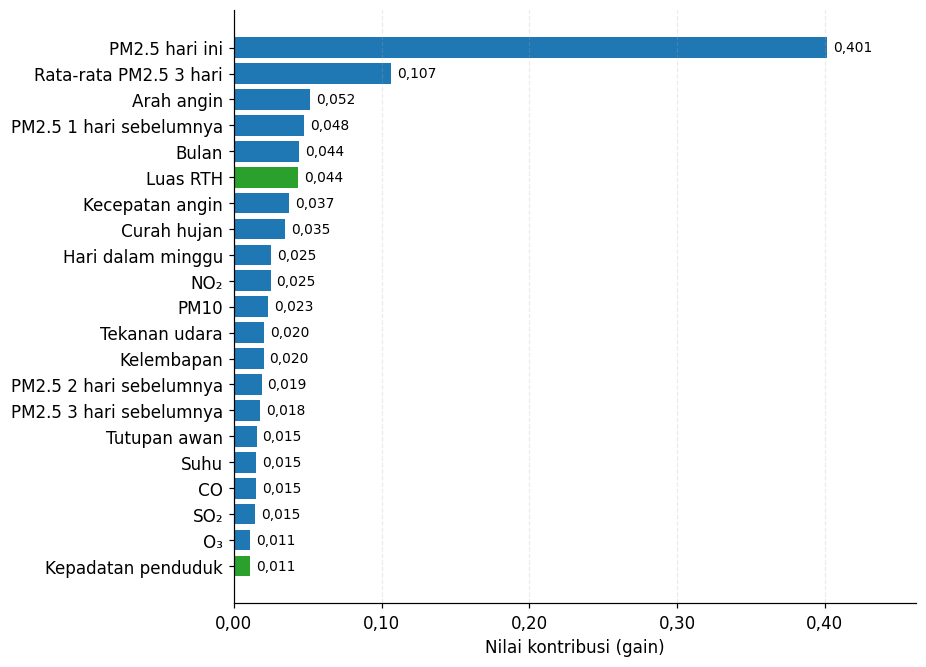

                  Bawaan  Random Search      PSO
max_depth            6.0         4.0000   3.0000
learning_rate        0.3         0.2802   0.1166
subsample            1.0         0.7652   0.8536
colsample_bytree     1.0         0.5891   0.9592
min_child_weight     1.0         7.0000  10.0000
reg_alpha            0.0         0.3838   2.0000
reg_lambda           1.0         0.7859   4.9807
  Horizon     MAE    RMSE    MAPE     R2  RMSE persistence
0     t+1   9.841  12.522  12.602  0.283            15.109
1     t+2  11.386  14.318  14.552  0.058            16.557
2     t+3  11.230  14.190  14.679  0.075            17.688
3     t+4  11.524  14.505  15.036  0.042            18.677
4     t+5  11.692  14.811  15.469  0.078            18.433
5     t+6  11.688  14.692  15.783  0.128            19.160
6     t+7  11.509  14.430  16.283  0.212            18.634
  Horizon  Bawaan  Random Search     PSO
0     t+1  13.486         12.796  12.522
1     t+2  15.725         14.460  14.318
2     t+3  16

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (9 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# GRAFIK & TABEL
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 12,
    'axes.labelsize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linestyle': '--',
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
koma = FuncFormatter(lambda v, _: f'{v:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
koma1 = FuncFormatter(lambda v, _: f'{v:.1f}'.replace('.', ','))
BIRU, ORANYE, HIJAU, MERAH = 'tab:blue', 'tab:orange', 'tab:green', 'tab:red'  # warna bawaan matplotlib/Colab


fig, ax = plt.subplots(figsize=(8, 4.2))
ax.step(range(len(riwayat)), riwayat, where='post', color=BIRU, lw=2, label='PSO')
ax.step(range(len(riwayat_rs)), riwayat_rs, where='post', color=ORANYE, lw=2, ls='--', label='Random Search')
ax.scatter([len(riwayat) - 1], [riwayat[-1]], color=BIRU, zorder=3)
ax.scatter([len(riwayat_rs) - 1], [riwayat_rs[-1]], color=ORANYE, zorder=3)
ax.annotate(f'{riwayat[-1]:.4f}'.replace('.', ','), (len(riwayat) - 1, riwayat[-1]),
            xytext=(-10, 10), textcoords='offset points', ha='right', color=BIRU)
ax.annotate(f'{riwayat_rs[-1]:.4f}'.replace('.', ','), (len(riwayat_rs) - 1, riwayat_rs[-1]),
            xytext=(-45, 0), textcoords='offset points', ha='right', va='center', color=ORANYE)
lo = min(min(riwayat), min(riwayat_rs)); hi = max(max(riwayat), max(riwayat_rs))
ax.set_ylim(lo - 0.08 * (hi - lo), hi + 0.05 * (hi - lo))
ax.set_xlabel(f'Iterasi (1 iterasi = {N_PARTIKEL} evaluasi)')
ax.set_ylabel('RMSE validasi terbaik')
ax.yaxis.set_major_formatter(koma); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(frameon=False)
plt.savefig('gambar_4_1_konvergensi.png'); plt.show()


H = [1, 2, 3, 4, 5, 6, 7]; lbl = [f't+{h}' for h in H]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(lbl, [persist[h]['RMSE'] for h in H], color=MERAH, marker='o', lw=2, label='Persistence')
ax.plot(lbl, [base[h]['RMSE'] for h in H], color=ORANYE, marker='o', lw=2, label='Hyperparameter bawaan')
ax.plot(lbl, [rs[h]['RMSE'] for h in H], color=HIJAU, marker='o', lw=2, label='Random Search')
ax.plot(lbl, [pso[h]['RMSE'] for h in H], color=BIRU, marker='o', lw=2, label='PSO')
ax.set_xlabel('Horizon prediksi'); ax.set_ylabel('RMSE (ISPU)')
ax.yaxis.set_major_formatter(koma1)
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.18))
plt.savefig('gambar_4_2_rmse_horizon.png'); plt.show()


_, _, _, pred1 = latih(FITUR, 1, BEST)
uji = df.loc[m_te, ['tanggal', 'stasiun', 'target_h1', 'target_h1_asli']].copy()
uji['prediksi'] = pred1; uji['tanggal_target'] = uji['tanggal'] + pd.Timedelta(days=1)
import matplotlib.dates as mdates
BLN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
st_list = sorted(uji['stasiun'].unique())
file_43 = []
for i, st in enumerate(st_list):
    d = uji[uji['stasiun'] == st]; a = d[d['target_h1_asli']]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(a['tanggal_target'], a['target_h1'], color=BIRU, lw=1.6, label='Aktual')
    ax.plot(d['tanggal_target'], d['prediksi'], color=ORANYE, lw=1.6, label='Prediksi')
    ax.axhline(100, color=MERAH, lw=0.8, ls='--', label='Batas Sedang/Tidak Sehat (100)')
    ax.set_ylabel('ISPU PM2.5'); ax.set_xlabel('Tanggal target prediksi (2025)')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: (lambda t: f'{t.day} {BLN[t.month-1]}')(mdates.num2date(v))))
    ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.18))
    nama = f'gambar_4_3{"abcde"[i]}_{st.split()[0]}.png'
    plt.savefig(nama); plt.show(); file_43.append(nama)

NAMA = {'kepadatan_penduduk_jiwa_km2': 'Kepadatan penduduk', 'luas_rth_km2': 'Luas RTH',
        'suhu_c': 'Suhu', 'kelembapan_pct': 'Kelembapan', 'curah_hujan_mm': 'Curah hujan',
        'tutupan_awan_pct': 'Tutupan awan', 'kecepatan_angin_kmh': 'Kecepatan angin',
        'tekanan_hpa': 'Tekanan udara', 'arah_angin_deg': 'Arah angin', 'pm10': 'PM10',
        'pm25': 'PM2.5 hari ini', 'so2': 'SO₂', 'co': 'CO', 'o3': 'O₃', 'no2': 'NO₂',
        'pm25_lag1': 'PM2.5 1 hari sebelumnya', 'pm25_lag2': 'PM2.5 2 hari sebelumnya',
        'pm25_lag3': 'PM2.5 3 hari sebelumnya', 'pm25_roll3': 'Rata-rata PM2.5 3 hari',
        'bulan': 'Bulan', 'hari': 'Hari dalam minggu'}
m1, _, _, _ = latih(FITUR, 1, BEST)
imp = pd.Series(m1.feature_importances_, index=FITUR).sort_values()
warna = [HIJAU if f in NOVELTY else BIRU for f in imp.index]
fig, ax = plt.subplots(figsize=(8, 7))
bars = ax.barh([NAMA[f] for f in imp.index], imp.values, color=warna)
for b, v in zip(bars, imp.values):
    ax.text(v + 0.004, b.get_y() + b.get_height() / 2, f'{v:.3f}'.replace('.', ','), va='center', fontsize=9)
ax.set_xlabel('Nilai kontribusi (gain)'); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(koma); ax.set_xlim(0, imp.max() * 1.15)
plt.savefig('gambar_4_4_feature_importance.png'); plt.show()

hp = pd.DataFrame({'Bawaan': DEF, 'Random Search': BEST_RS, 'PSO': BEST}).drop(index='n_estimators')
metrik_tabel = pd.DataFrame([{**{'Horizon': f't+{h}'}, **{k: round(v, 3) for k, v in pso[h].items()},
                              'RMSE persistence': round(persist[h]['RMSE'], 3)} for h in H])
banding = pd.DataFrame([{'Horizon': f't+{h}', 'Bawaan': round(base[h]['RMSE'], 3),
                         'Random Search': round(rs[h]['RMSE'], 3), 'PSO': round(pso[h]['RMSE'], 3)} for h in H])
peringkat = imp.sort_values(ascending=False).rename(index=NAMA).round(4).reset_index()
peringkat.columns = ['Fitur', 'Gain']; peringkat.index += 1
with pd.ExcelWriter('tabel_bab4.xlsx') as w:
    hp.round(4).to_excel(w, sheet_name='Hyperparameter')
    metrik_tabel.to_excel(w, sheet_name='Metrik PSO', index=False)
    banding.to_excel(w, sheet_name='Bawaan vs RS vs PSO', index=False)
    peringkat.to_excel(w, sheet_name='Feature importance')
print(hp.round(4)); print(metrik_tabel); print(banding)

from google.colab import files
for f in ['gambar_4_1_konvergensi.png', 'gambar_4_2_rmse_horizon.png', *file_43,
          'gambar_4_4_feature_importance.png', 'tabel_bab4.xlsx']:
    files.download(f)

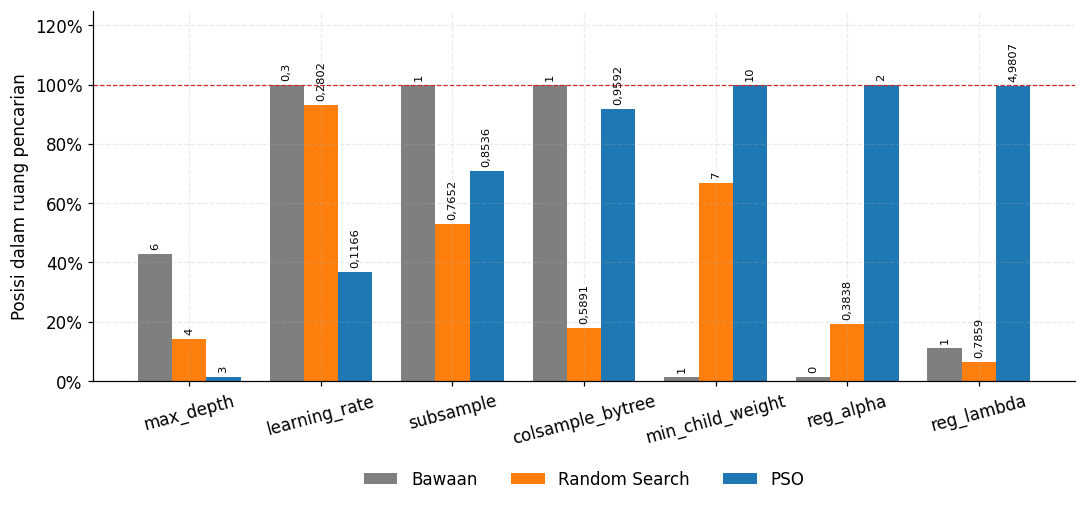

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# GAMBAR PERBANDINGAN HYPERPARAMETER BAWAAN vs RANDOM SEARCH vs PSO
import numpy as np, matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
nama = ['max_depth','learning_rate','subsample','colsample_bytree','min_child_weight','reg_alpha','reg_lambda']
konfig = {'Bawaan': DEF, 'Random Search': BEST_RS, 'PSO': BEST}
warna = {'Bawaan': 'tab:gray', 'Random Search': 'tab:orange', 'PSO': 'tab:blue'}
x = np.arange(len(nama)); w = 0.26
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, (lbl, p) in enumerate(konfig.items()):
    nilai = np.array([p[k] for k in nama], dtype=float)
    posisi = (nilai - BB) / (BA - BB) * 100
    bars = ax.bar(x + (i - 1) * w, np.maximum(posisi, 1.5), w, color=warna[lbl], label=lbl)
    for b, v in zip(bars, nilai):
        teks = f'{v:.0f}' if v == int(v) else f'{v:.4f}'.rstrip('0').rstrip('.').replace('.', ',')
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5, teks,
                ha='center', va='bottom', fontsize=7.5, rotation=90)
ax.set_xticks(x); ax.set_xticklabels(nama, rotation=15)
ax.set_ylabel('Posisi dalam ruang pencarian'); ax.set_ylim(0, 125)
ax.yaxis.set_major_formatter(PercentFormatter())
ax.axhline(100, color='tab:red', lw=0.8, ls='--')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); plt.savefig('gambar_hyperparameter.png', dpi=300, bbox_inches='tight'); plt.show()
from google.colab import files; files.download('gambar_hyperparameter.png')

ValueError: The number of FixedLocator locations (7), usually from a call to set_ticks, does not match the number of labels (3).

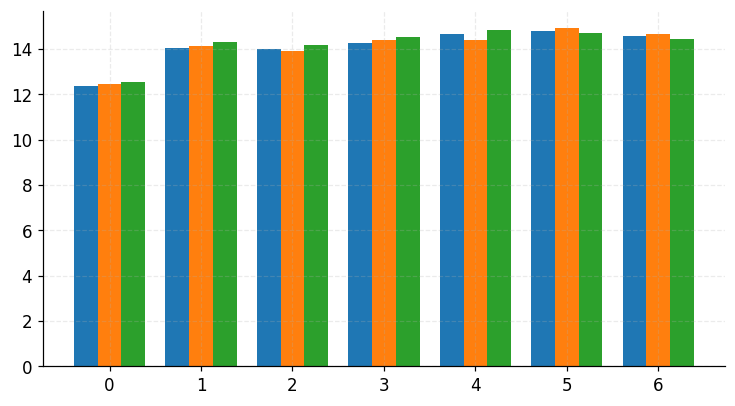

In [23]:
# 17. SKENARIO S1, S2, S3 + UJI DIEBOLD-MARIANO
sk = {'S1 · tanpa variabel statis': [], 'S2 · + penanda stasiun': [], 'S3 · + kepadatan & RTH': []}
dm = []
for h in H:
    _, _, r1, p1 = latih(DASAR, h, BEST)
    _, _, r2, _  = latih(DASAR + ST, h, BEST)
    _, _, r3, p3 = latih(FITUR, h, BEST)
    for key, r in zip(sk, [r1, r2, r3]): sk[key].append(r['RMSE'])
    a = df.loc[m_te, f'target_h{h}_asli'].values.astype(bool)
    yt = df.loc[m_te, f'target_h{h}'].values[a]
    s, pv = dm_test(yt, p1[a], p3[a], h)
    dm.append({'Horizon': f't+{h}', 'DM': round(s, 3), 'p-value': round(pv, 4),
               'Keterangan': 'Signifikan' if pv < 0.05 else 'Tidak signifikan'})
fig, ax = plt.subplots(figsize=(8, 4.2)); w = 0.26
for i, ((key, v), c) in enumerate(zip(sk.items(), [BIRU, ORANYE, HIJAU])):
    ax.bar(np.arange(7) + (i - 1) * w, v, w, color=c, label=key)
ax.set_xticks(range(7)); ax.set_xticklabels(lbl); ax.set_ylim(min(min(v) for v in sk.values()) - 1, None)
ax.set_xlabel('Horizon prediksi'); ax.set_ylabel('RMSE (ISPU)'); ax.grid(axis='x', visible=False)
ax.yaxis.set_major_formatter(koma1)
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.18), fontsize=9.5)
plt.savefig('gambar_4_5_skenario.png'); plt.show()

tabel_sk = pd.DataFrame(sk, index=lbl).round(3); tabel_dm = pd.DataFrame(dm)
with pd.ExcelWriter('tabel_skenario.xlsx') as wr:
    tabel_sk.to_excel(wr, sheet_name='RMSE skenario'); tabel_dm.to_excel(wr, sheet_name='Uji DM', index=False)
print(tabel_sk); print(tabel_dm)
files.download('gambar_4_5_skenario.png'); files.download('tabel_skenario.xlsx')

In [ ]:
   !lscpu | grep "Model name"; nproc; free -h | head -2; python --version